Aprendizado de máquina com Random Forest e Redes Neurais para dataset de sinais vitais. O objetivo do treinamento desse notebook é recuperar os dados referentes ao valor e classes da gravidade da saúde dos pacientes.   

## 1. Configuração e carregamento dos dados

In [94]:
import random, os
import numpy as np

SEED = 76

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

In [95]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# do ml
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (f1_score, r2_score, root_mean_squared_error, mean_absolute_error,
                             classification_report, confusion_matrix, accuracy_score, recall_score)
from sklearn.model_selection import train_test_split

# visualizacoes
from sklearn.metrics import ConfusionMatrixDisplay

In [96]:
df_label = pd.read_csv("dados/02_treino_sinais_vitais_com_label.csv", header=None, names=['id', 'pSist', 'pDiast', 'qPA', 'pulso', 'resp', 'gravidade', 'rotulo_saida'])

In [97]:
df_label.head()

,id,pSist,pDiast,qPA,pulso,resp,gravidade,rotulo_saida
0,1,13.592433,12.220855,8.416754,75.921057,21.635259,40.000000,2
1,2,15.775386,13.586879,8.725890,63.813564,19.718734,41.530427,2
2,3,3.649369,1.904802,0.000000,197.210213,19.045471,52.730745,3
3,4,17.264362,13.700638,8.733333,143.636181,17.621141,34.679911,2
4,5,12.705183,9.485389,1.747626,82.636672,12.209535,69.375882,3


In [98]:
# colunas nao usadas
df_label = df_label.drop(columns=['pDiast', 'pSist'])

## 2. Random Forest

### Análise Exploratória

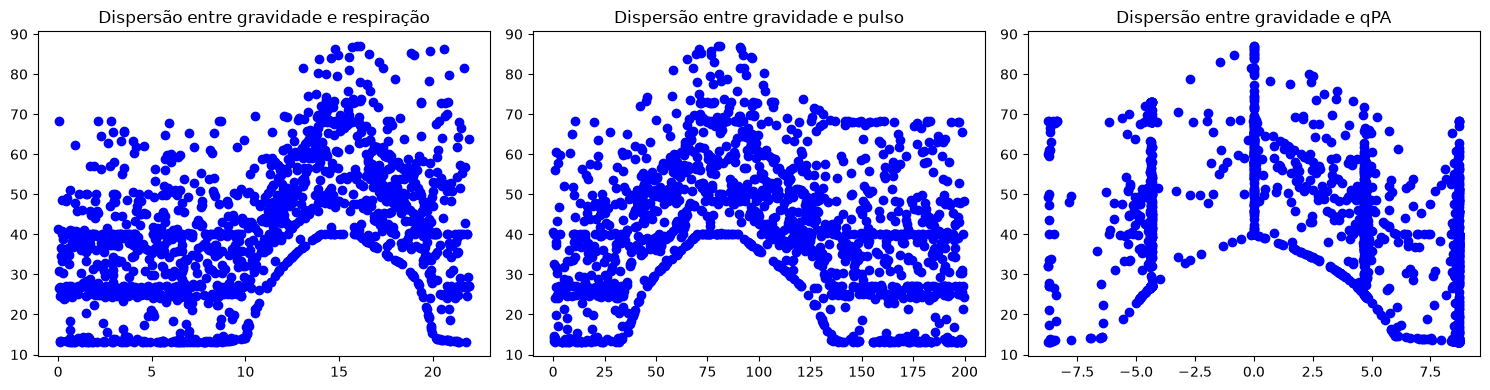

In [99]:
gravidade = df_label['gravidade']

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

ax1.scatter(x=df_label['resp'], y=gravidade, color='blue')
ax1.set_title("Dispersão entre gravidade e respiração")

ax2.scatter(x=df_label['pulso'], y=gravidade, color='blue')
ax2.set_title("Dispersão entre gravidade e pulso")

ax3.scatter(x=df_label['qPA'], y=gravidade, color='blue')
ax3.set_title("Dispersão entre gravidade e qPA")

plt.tight_layout()
plt.show()

In [100]:
contagem = df_label['rotulo_saida'].value_counts()
porcentagem = df_label['rotulo_saida'].value_counts(normalize=True) * 100

distribuicao = pd.DataFrame({'Total': contagem, 'Porcentagem (%)': porcentagem})
print(distribuicao)

              Total  Porcentagem (%)
rotulo_saida                        
2               832        55.466667
3               404        26.933333
1               234        15.600000
4                30         2.000000


In [101]:
df_label.describe()

,id,qPA,pulso,resp,gravidade,rotulo_saida
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,750.500000,2.414994,101.196190,10.854599,41.427388,2.153333
std,433.157015,5.128025,57.872687,6.277191,16.590523,0.694366
min,1.000000,-8.732919,0.046213,0.007174,13.222719,1.000000
25%,375.750000,-0.861911,50.511863,5.548182,27.873461,2.000000
50%,750.500000,4.237224,100.887445,10.963869,40.000000,2.000000
75%,1125.250000,6.764517,151.354666,16.412472,51.958481,3.000000
max,1500.000000,8.733333,199.954625,21.959598,87.000000,4.000000


### Random Forest - Treinamento

Prever o valor da gravidade dos pacientes com três sinais vitais: qualidade da pressão, pulso e respiração

In [102]:
df_label.columns

Index(['id', 'qPA', 'pulso', 'resp', 'gravidade', 'rotulo_saida'], dtype='object')

In [103]:
X = df_label[['qPA', 'pulso', 'resp']]
y = df_label["gravidade"]         
classi_y = df_label["rotulo_saida"] 

X_treino, X_teste, y_treino, y_teste, classi_y_treino, classi_y_teste = train_test_split(
    X, y, classi_y, test_size=0.2, random_state=SEED, stratify=classi_y
)

print(classi_y_teste.value_counts().sort_index())

rotulo_saida
1     47
2    166
3     81
4      6
Name: count, dtype: int64


In [104]:
model = RandomForestRegressor(
    n_estimators=256,
    n_jobs=-1,
    random_state=SEED
    )

model.fit(X_treino, y_treino)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",256
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",76
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [105]:
y_pred = model.predict(X_teste)

r2 = r2_score(y_teste, y_pred)
rmse = root_mean_squared_error(y_teste, y_pred)
mae = mean_absolute_error(y_teste, y_pred)

print(f"R² Score: {r2:.4f}")
print(f"RMSE Score: {rmse:.4f}")
print(f"MAE Score: {mae:.4f}")

R² Score: 0.9769
RMSE Score: 2.5243
MAE Score: 1.6006


Reconstrução das classes da gravidade dos pacientes - Classificação

In [142]:
classficador = RandomForestClassifier(
    criterion="gini",
    random_state=SEED,
    n_estimators=16 # troca valores de arvores aqui
)   
classficador.fit(X_treino, classi_y_treino)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",16
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",76
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In [143]:
resul = classficador.predict(X_teste)

In [144]:
f1_macro = f1_score(classi_y_teste, resul, average='macro')
print(f1_macro)

acc = accuracy_score(classi_y_teste, resul)
print(f"Acurácia: {acc:.4f}\n")

rec_macro = recall_score(classi_y_teste, resul, average="macro")
print(f"Recall (macro): {rec_macro:.4f}\n")


0.8655643111599156
Acurácia: 0.9300

Recall (macro): 0.8292



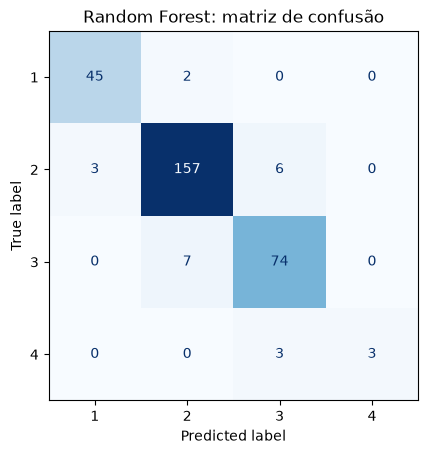

In [145]:
ConfusionMatrixDisplay.from_predictions(
    classi_y_teste, resul, labels=[1, 2, 3, 4],
    cmap='Blues', colorbar=False
)
plt.title('Random Forest: matriz de confusão')
plt.show()

In [110]:
resul_via_g = np.digitize(y_pred, bins=[25, 50, 75]) + 1

print("F1 macro (classificação direta):", round(f1_score(classi_y_teste, resul, average='macro'), 4))
print("F1 macro (via gravidade):", round(f1_score(classi_y_teste, resul_via_g, average='macro'), 4))
print(confusion_matrix(classi_y_teste, resul_via_g, labels=[1, 2, 3, 4]))

F1 macro (classificação direta): 0.8623
F1 macro (via gravidade): 0.8759
[[ 43   4   0   0]
 [  0 158   8   0]
 [  0   2  79   0]
 [  0   0   3   3]]
